# Task 2 — Named Entity Recognition: CoNLL-2003
**LSTM vs BiLSTM vs BiLSTM-CRF | Exact entity-level evaluation | Kaggle GPU-ready**

This notebook uses your team's preprocessed local files. It does **not** download, re-annotate, or train anything until you run it.

**Models:** unidirectional LSTM, BiLSTM, and the optional BiLSTM-CRF extension.

**Evaluation:** exact entity-span micro Precision, Recall, F1; per-entity-type results; supporting token metrics; missed entities, boundary errors, type errors, and spurious predictions. Epoch/checkpoint selection uses validation entity Micro-F1. Test results are reserved for final evaluation.

The attached `data_summary.json` identifies `extraordinarylab/conll2003`, with `PER`, `ORG`, `LOC`, and `MISC`. The provided `test.jsonl` uses sentence-level arrays `tokens`, `ner_tags` (BIO), and `ner_tags_bioes` (BIOES). In this chat, I could inspect `test.jsonl` and `data_summary.json`, but `train.jsonl`, `val.jsonl`, and `vocab.json` were not attached. Add those three files to a Kaggle Dataset input alongside the test file, or set `DATA_DIR` below.

## 0. Setup and input discovery

Ensure a GPU is enabled if you want to accelerate training. The loader searches the specified `DATA_DIR`, your current working directory, or a nested subdirectory.

Required files: `train.jsonl`, `val.jsonl`, `test.jsonl`, and `vocab.json`. `data_summary.json` is optional.

In [7]:
import os, json, time, random, re, platform, shutil
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import classification_report

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = Path("ner_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = "."  # Set this to your local data folder if your files are in a specific directory

# Training defaults: adjust batch size/epochs based on your local device capacity.
EMBED_DIM, HIDDEN_DIM, DROPOUT = 100, 128, 0.35
BATCH_SIZE = 64 if torch.cuda.is_available() else 32
MAX_EPOCHS, PATIENCE = 15, 4
LEARNING_RATE, WEIGHT_DECAY, GRAD_CLIP = 1e-3, 1e-4, 1.0
NUM_WORKERS = 2


def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
print("Python:", platform.python_version(), "| PyTorch:", torch.__version__, "| Device:", DEVICE)
if torch.cuda.is_available(): print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.16 | PyTorch: 2.11.0+cpu | Device: cpu


In [8]:
REQUIRED_FILES = ["train.jsonl", "val.jsonl", "test.jsonl", "vocab.json"]

def find_file(filename):
    roots = []
    if DATA_DIR: roots.append(Path(DATA_DIR))
    roots += [Path.cwd(), Path("data")]
    seen = set()
    for root in roots:
        if not root.exists(): continue
        try: key = str(root.resolve())
        except Exception: key = str(root)
        if key in seen: continue
        seen.add(key)
        candidate = root / filename
        if candidate.is_file(): return candidate
        try:
            for candidate in root.rglob(filename):
                if candidate.is_file(): return candidate
        except (PermissionError, OSError):
            pass
    return None

FILE_PATHS = {name: find_file(name) for name in REQUIRED_FILES}
FILE_PATHS["data_summary.json"] = find_file("data_summary.json")
for name, path in FILE_PATHS.items(): print(f"{name}: {path if path else 'NOT FOUND'}")
missing = [name for name in REQUIRED_FILES if FILE_PATHS[name] is None]
if missing:
    raise FileNotFoundError(f"Missing files {missing}. Place them in the working directory, a './data' folder, or set DATA_DIR.")

train.jsonl: train.jsonl
val.jsonl: val.jsonl
test.jsonl: test.jsonl
vocab.json: vocab.json
data_summary.json: data_summary.json


## 1. Load and validate the provided annotations

Each line is one sentence. `tokens` and `ner_tags` must have equal length. BIOES tags are preferred when present in all splits; otherwise the notebook converts the team-provided BIO annotations to BIOES without changing token positions. The two formats are alternative annotation schemes for the same tokens—not separate samples.

In [9]:
def read_jsonl(path):
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line_no, line in enumerate(f, 1):
            if not line.strip(): continue
            try: row = json.loads(line)
            except json.JSONDecodeError as e: raise ValueError(f"Invalid JSON at {path}:{line_no}: {e}")
            if "tokens" not in row or "ner_tags" not in row:
                raise ValueError(f"Expected tokens and ner_tags at {path}:{line_no}")
            row["tokens"] = [str(x) for x in row["tokens"]]
            row["ner_tags"] = [str(x) for x in row["ner_tags"]]
            if len(row["tokens"]) != len(row["ner_tags"]):
                raise ValueError(f"Token/tag count mismatch at {path}:{line_no}")
            if "ner_tags_bioes" in row:
                row["ner_tags_bioes"] = [str(x) for x in row["ner_tags_bioes"]]
                if len(row["tokens"]) != len(row["ner_tags_bioes"]):
                    raise ValueError(f"Token/BIOES count mismatch at {path}:{line_no}")
            rows.append(row)
    if not rows: raise ValueError(f"No rows found in {path}")
    return rows

train_rows = read_jsonl(FILE_PATHS["train.jsonl"])
val_rows = read_jsonl(FILE_PATHS["val.jsonl"])
test_rows = read_jsonl(FILE_PATHS["test.jsonl"])
with open(FILE_PATHS["vocab.json"], "r", encoding="utf-8") as f: vocab_data = json.load(f)

print(f"Sentence counts | train={len(train_rows):,} val={len(val_rows):,} test={len(test_rows):,}")
print("Example row:", json.dumps(test_rows[0], ensure_ascii=False, indent=2)[:2000])
print("Vocab keys:", list(vocab_data.keys()) if isinstance(vocab_data, dict) else type(vocab_data))

Sentence counts | train=14,041 val=3,250 test=3,453
Example row: {
  "tokens": [
    "SOCCER",
    "-",
    "JAPAN",
    "GET",
    "LUCKY",
    "WIN",
    ",",
    "CHINA",
    "IN",
    "SURPRISE",
    "DEFEAT",
    "."
  ],
  "ner_tags": [
    "O",
    "O",
    "B-LOC",
    "O",
    "O",
    "O",
    "O",
    "B-PER",
    "O",
    "O",
    "O",
    "O"
  ],
  "ner_tags_bioes": [
    "O",
    "O",
    "S-LOC",
    "O",
    "O",
    "O",
    "O",
    "S-PER",
    "O",
    "O",
    "O",
    "O"
  ]
}
Vocab keys: ['word2idx', 'char2idx', 'tag2idx', 'tag2idx_bioes']


,split,sentences,tokens,mean_sentence_length,max_sentence_length,PER,ORG,LOC,MISC
0,train,14041,203618,14.50,113,6600,6321,7140,3438
1,validation,3250,51360,15.80,109,1842,1341,1837,922
2,test,3453,46427,13.45,124,1617,1661,1668,702


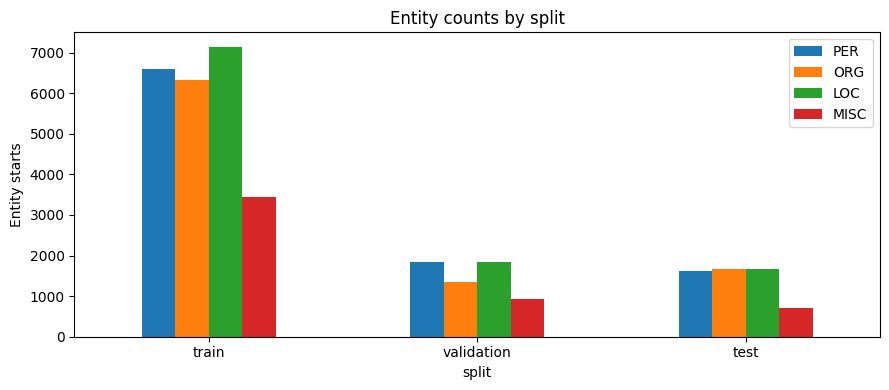

Token/label alignment validated; active scheme: BIOES


In [10]:
def bio_to_bioes(tags):
    out = list(tags)
    i = 0
    while i < len(tags):
        tag = tags[i]
        if tag == "O" or "-" not in tag:
            out[i] = tag; i += 1; continue
        prefix, ent_type = tag.split("-", 1)
        if prefix == "B":
            j = i + 1
            while j < len(tags) and tags[j] == f"I-{ent_type}": j += 1
            if j == i + 1: out[i] = f"S-{ent_type}"
            else:
                out[i] = f"B-{ent_type}"
                for k in range(i + 1, j - 1): out[k] = f"I-{ent_type}"
                out[j - 1] = f"E-{ent_type}"
            i = j
        elif prefix == "I":
            # Defensive repair for malformed orphan I tags.
            out[i] = f"S-{ent_type}"; i += 1
        else:
            out[i] = tag; i += 1
    return out

ALL_ROWS = train_rows + val_rows + test_rows
HAS_BIOES = all("ner_tags_bioes" in row for row in ALL_ROWS)
SCHEME = "BIOES" if HAS_BIOES else "BIOES_FROM_BIO"

def row_tags(row):
    return row["ner_tags_bioes"] if "ner_tags_bioes" in row else bio_to_bioes(row["ner_tags"])

ENTITY_TYPES = ["PER", "ORG", "LOC", "MISC"]
def count_entities(rows):
    counts = Counter()
    for row in rows:
        for tag in row_tags(row):
            if tag.startswith(("B-", "S-")): counts[tag.split("-", 1)[1]] += 1
    return counts

def split_stats(name, rows):
    counts = count_entities(rows)
    lengths = [len(r["tokens"]) for r in rows]
    return {"split":name, "sentences":len(rows), "tokens":sum(lengths),
            "mean_sentence_length":round(float(np.mean(lengths)), 2), "max_sentence_length":max(lengths),
            **{t:counts[t] for t in ENTITY_TYPES}}

split_summary = pd.DataFrame([split_stats("train", train_rows), split_stats("validation", val_rows), split_stats("test", test_rows)])
display(split_summary)
split_summary.to_csv(OUT_DIR / "split_summary.csv", index=False)
ax = split_summary.set_index("split")[ENTITY_TYPES].plot(kind="bar", figsize=(9,4))
ax.set_title("Entity counts by split"); ax.set_ylabel("Entity starts"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
for split_name, rows in [("train",train_rows),("validation",val_rows),("test",test_rows)]:
    assert all(len(r["tokens"]) == len(row_tags(r)) for r in rows)
print("Token/label alignment validated; active scheme:", SCHEME)

## 2. Vocabulary, normalization, unknown words, and tag IDs

The supplied `vocab.json` is reused. The notebook tests raw, lowercase, and lowercase-with-digits-replaced-by-`0` variants against the supplied `word2idx`, selecting whichever has best **training-token coverage**. It uses `<UNK>` for any unseen token and a separate `<PAD>` ID for batch padding. Labels are mapped to contiguous IDs from tag names, while the file's tag vocabulary is inspected for consistency.

This is normalization only: it does not alter sentence token count or reorder tokens, so token-label alignment is preserved.

In [11]:
def get_map(obj, key):
    if isinstance(obj, dict) and isinstance(obj.get(key), dict): return obj[key]
    return {}

word2idx = get_map(vocab_data, "word2idx")
if not word2idx and isinstance(vocab_data, dict) and vocab_data and all(isinstance(v, int) for v in vocab_data.values()):
    word2idx = vocab_data
word2idx = {str(k):int(v) for k,v in word2idx.items()}

def norm_raw(x): return x
def norm_lower(x): return x.lower()
def norm_digit0(x): return re.sub(r"\d", "0", x.lower())
normalizers = {"raw":norm_raw, "lowercase":norm_lower, "lowercase_digit0":norm_digit0}

train_tokens = [token for row in train_rows for token in row["tokens"]]
if word2idx:
    coverage = {name:sum(fn(t) in word2idx for t in train_tokens)/max(len(train_tokens),1) for name,fn in normalizers.items()}
    NORMALIZATION = max(coverage, key=coverage.get)
    normalize_token = normalizers[NORMALIZATION]
    print("Training vocabulary coverage:", {k:round(v,4) for k,v in coverage.items()})
else:
    NORMALIZATION = "lowercase_digit0"
    normalize_token = norm_digit0
    counts = Counter(normalize_token(t) for t in train_tokens)
    word2idx = {"<PAD>":0, "<UNK>":1}
    for token, _ in counts.most_common(50000-2):
        if token not in word2idx: word2idx[token] = len(word2idx)
    print("No word2idx map found; built a fallback vocabulary from train only.")


def special_id(mapping, names):
    for name in names:
        if name in mapping: return int(mapping[name])
    return None

PAD_ID = special_id(word2idx, ["<PAD>","<pad>","[PAD]","PAD","_PAD_"])
UNK_ID = special_id(word2idx, ["<UNK>","<unk>","[UNK]","UNK","_UNK_","<OOV>"])
next_id = max(word2idx.values(), default=-1) + 1
if PAD_ID is None: PAD_ID=next_id; word2idx["<PAD>"]=PAD_ID; next_id+=1
if UNK_ID is None: UNK_ID=next_id; word2idx["<UNK>"]=UNK_ID; next_id+=1
if PAD_ID == UNK_ID: raise ValueError("PAD and UNK IDs must differ.")
VOCAB_SIZE = max(word2idx.values()) + 1

# Label inventory is derived from training annotations and the known CoNLL tag schema.
train_tag_set = set(tag for row in train_rows for tag in row_tags(row))
all_tag_set = set(tag for row in ALL_ROWS for tag in row_tags(row))
BIOES_SCHEMA_TAGS = {"O"}
for ent in ENTITY_TYPES:
    BIOES_SCHEMA_TAGS.update({f"B-{ent}", f"I-{ent}", f"E-{ent}", f"S-{ent}"})
file_tag_map = get_map(vocab_data, "tag2idx_bioes")
if file_tag_map:
    ordered = [tag for tag, _ in sorted(file_tag_map.items(), key=lambda kv:int(kv[1])) if tag in (train_tag_set | all_tag_set)]
else:
    ordered = sorted(train_tag_set | all_tag_set)
tag_names = ["O"] + [tag for tag in ordered if tag != "O"]
tag_names += [tag for tag in sorted(all_tag_set) if tag not in tag_names]
tag2id = {tag:i for i,tag in enumerate(tag_names)}
id2tag = {i:tag for tag,i in tag2id.items()}
N_TAGS = len(tag_names)

def encode_tokens(tokens): return [word2idx.get(normalize_token(t), UNK_ID) for t in tokens]
def encode_tags(row): return [tag2id[t] for t in row_tags(row)]

def oov_stats(name, rows):
    tokens = [t for row in rows for t in row["tokens"]]
    oov = sum(normalize_token(t) not in word2idx for t in tokens)
    return {"split":name,"tokens":len(tokens),"oov_tokens":oov,"oov_rate":oov/max(len(tokens),1)}

vocab_oov = pd.DataFrame([oov_stats("train",train_rows),oov_stats("validation",val_rows),oov_stats("test",test_rows)])
display(vocab_oov)
vocab_oov.to_csv(OUT_DIR / "oov_statistics.csv", index=False)
print("Normalization:", NORMALIZATION, "| vocab size:", VOCAB_SIZE, "| PAD:", PAD_ID, "| UNK:", UNK_ID)
print("Tag scheme:", SCHEME, "| tag count:", N_TAGS, "| tags:", tag_names)

Training vocabulary coverage: {'raw': 0.6622, 'lowercase': 0.9107, 'lowercase_digit0': 1.0}


,split,tokens,oov_tokens,oov_rate
0,train,203618,0,0.000000
1,validation,51360,3060,0.059579
2,test,46427,3847,0.082861


Normalization: lowercase_digit0 | vocab size: 17494 | PAD: 0 | UNK: 1
Tag scheme: BIOES | tag count: 17 | tags: ['O', 'B-PER', 'I-PER', 'E-PER', 'S-PER', 'B-ORG', 'I-ORG', 'E-ORG', 'S-ORG', 'B-LOC', 'I-LOC', 'E-LOC', 'S-LOC', 'B-MISC', 'I-MISC', 'E-MISC', 'S-MISC']


## 3. Batch padding and token-label alignment

Every sentence becomes two same-length integer sequences. `pad_sequence` pads word IDs with `PAD_ID` and tags with `O` only as a placeholder; an explicit mask/length ensures padded positions are excluded from the cross-entropy loss, token scores, and CRF path. The models process complete sentences—no truncation is applied—so entities crossing a truncation boundary cannot be lost.

In [12]:
class NERDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows
        self.x = [torch.tensor(encode_tokens(r["tokens"]), dtype=torch.long) for r in rows]
        self.y = [torch.tensor(encode_tags(r), dtype=torch.long) for r in rows]
        for x,y in zip(self.x,self.y):
            if len(x) != len(y): raise ValueError("Token-label alignment mismatch")
    def __len__(self): return len(self.rows)
    def __getitem__(self, i): return self.x[i], self.y[i], len(self.x[i]), i

def collate_ner(batch):
    xs, ys, lengths, indices = zip(*batch)
    x_pad = nn.utils.rnn.pad_sequence(xs, batch_first=True, padding_value=PAD_ID)
    y_pad = nn.utils.rnn.pad_sequence(ys, batch_first=True, padding_value=tag2id["O"])
    return x_pad, y_pad, torch.tensor(lengths, dtype=torch.long), torch.tensor(indices, dtype=torch.long)

train_ds, val_ds, test_ds = NERDataset(train_rows), NERDataset(val_rows), NERDataset(test_rows)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_ner,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_ner,
                        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_ner,
                         num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
xb, yb, lb, ib = next(iter(train_loader))
print("Word batch shape:", tuple(xb.shape), "| tag batch shape:", tuple(yb.shape))
print("Real sentence lengths:", lb[:10].tolist())
print("First padded batch row, decoded:", list(zip(train_rows[int(ib[0])]["tokens"], [id2tag[int(i)] for i in yb[0,:int(lb[0])]])))

Word batch shape: (32, 47) | tag batch shape: (32, 47)
Real sentence lengths: [10, 10, 15, 2, 5, 23, 4, 41, 2, 4]
First padded batch row, decoded: [('SOCCER', 'O'), ('-', 'O'), ('RUSSIA', 'S-LOC'), ('AND', 'O'), ('BRAZIL', 'S-LOC'), ('DRAW', 'O'), ('2-2', 'O'), ('IN', 'O'), ('FRIENDLY', 'O'), ('.', 'O')]


## 4. Exact entity extraction and scoring

A predicted entity is represented by `(sentence index, start token, end token exclusive, entity type)`. It is correct only when all four fields match the gold entity. Micro Precision/Recall/F1 are computed from the intersection of gold and predicted span sets. Scores are also reported independently for PER, ORG, LOC, and MISC. This is the primary metric; token-level accuracy is only supplementary.

In [13]:
def parse_tag(tag):
    if tag == "O" or "-" not in tag: return "O", None
    prefix, entity_type = tag.split("-",1)
    if prefix not in {"B","I","E","S"}: return "O", None
    return prefix, entity_type

def tags_to_spans(tags):
    spans=[]; active_type=None; active_start=None
    def close(end):
        nonlocal active_type, active_start
        if active_type is not None: spans.append((active_start,end,active_type))
        active_type=None; active_start=None
    for i,tag in enumerate(tags):
        p,t = parse_tag(tag)
        if p == "O": close(i)
        elif p == "S": close(i); spans.append((i,i+1,t))
        elif p == "B": close(i); active_type,active_start=t,i
        elif p == "I":
            if active_type != t: close(i); active_type,active_start=t,i
        elif p == "E":
            if active_type == t: close(i+1)
            else: close(i); spans.append((i,i+1,t))
    close(len(tags))
    return spans

def score_spans(rows, gold_sequences, pred_sequences):
    gold={(si,s,e,t) for si, tags in enumerate(gold_sequences) for s,e,t in tags_to_spans(tags)}
    pred={(si,s,e,t) for si, tags in enumerate(pred_sequences) for s,e,t in tags_to_spans(tags)}
    tp=len(gold & pred); p=tp/len(pred) if pred else 0.0; r=tp/len(gold) if gold else 0.0
    f=2*p*r/(p+r) if p+r else 0.0
    rows_out=[]
    for typ in ENTITY_TYPES:
        g={x for x in gold if x[3]==typ}; q={x for x in pred if x[3]==typ}; tpi=len(g&q)
        pi=tpi/len(q) if q else 0.0; ri=tpi/len(g) if g else 0.0; fi=2*pi*ri/(pi+ri) if pi+ri else 0.0
        rows_out.append({"entity_type":typ,"precision":pi,"recall":ri,"f1":fi,"gold_support":len(g),"predicted":len(q),"true_positive":tpi})
    return {"precision":p,"recall":r,"f1":f,"gold_entities":len(gold),"predicted_entities":len(pred),
            "true_positive":tp,"per_type":pd.DataFrame(rows_out),"gold_spans":gold,"pred_spans":pred}

gold_val_tags=[row_tags(r) for r in val_rows]
gold_test_tags=[row_tags(r) for r in test_rows]
assert tags_to_spans(["B-PER","E-PER","O","S-LOC"]) == [(0,2,"PER"),(3,4,"LOC")]
print("Exact-span extraction sanity check passed.")

Exact-span extraction sanity check passed.


## 5. Architectures: LSTM, BiLSTM, and BiLSTM-CRF

The recurrent encoder embeds tokens and emits a tag score at each token. LSTM reads left-to-right; BiLSTM concatenates forward and backward representations. The optional CRF layer scores full tag sequences and uses Viterbi decoding, with transition constraints for legal BIOES sequences. This can encourage consistent spans, but its benefit must be established from validation/test results rather than assumed.

In [14]:
def parse_prefix(tag):
    if tag == "O" or "-" not in tag: return "O", None
    return tag.split("-",1)

def allowed_start(tag): return parse_prefix(tag)[0] in {"O","B","S"}
def allowed_end(tag): return parse_prefix(tag)[0] in {"O","E","S"}
def allowed_transition(prev_tag, next_tag):
    pp,pt=parse_prefix(prev_tag); np_,nt=parse_prefix(next_tag)
    if pp in {"B","I"}: return np_ in {"I","E"} and pt==nt
    return np_ in {"O","B","S"}

class LinearChainCRF(nn.Module):
    def __init__(self, labels):
        super().__init__(); n=len(labels)
        self.transitions=nn.Parameter(torch.empty(n,n))
        self.start_transitions=nn.Parameter(torch.empty(n)); self.end_transitions=nn.Parameter(torch.empty(n))
        nn.init.uniform_(self.transitions,-0.1,0.1); nn.init.uniform_(self.start_transitions,-0.1,0.1); nn.init.uniform_(self.end_transitions,-0.1,0.1)
        allowed=torch.tensor([[allowed_transition(a,b) for b in labels] for a in labels],dtype=torch.float32)
        start=torch.tensor([allowed_start(t) for t in labels],dtype=torch.float32)
        end=torch.tensor([allowed_end(t) for t in labels],dtype=torch.float32)
        self.register_buffer("trans_constraint", torch.where(allowed.bool(),0.0,-10000.0))
        self.register_buffer("start_constraint", torch.where(start.bool(),0.0,-10000.0))
        self.register_buffer("end_constraint", torch.where(end.bool(),0.0,-10000.0))
    def trans(self): return self.transitions+self.trans_constraint
    def start(self): return self.start_transitions+self.start_constraint
    def end(self): return self.end_transitions+self.end_constraint
    def log_partition(self, emissions, mask):
        score=self.start().unsqueeze(0)+emissions[:,0]
        trans=self.trans().unsqueeze(0)
        for t in range(1,emissions.size(1)):
            candidates=score.unsqueeze(2)+trans
            next_score=torch.logsumexp(candidates,dim=1)+emissions[:,t]
            score=torch.where(mask[:,t].unsqueeze(1),next_score,score)
        return torch.logsumexp(score+self.end().unsqueeze(0),dim=1)
    def gold_score(self, emissions, tags, mask):
        b=torch.arange(emissions.size(0),device=emissions.device)
        score=self.start()[tags[:,0]]+emissions[b,0,tags[:,0]]
        trans=self.trans()
        for t in range(1,emissions.size(1)):
            step=trans[tags[:,t-1],tags[:,t]]+emissions[b,t,tags[:,t]]
            score=score+step*mask[:,t].float()
        lengths=mask.long().sum(1); last=tags[b,lengths-1]
        return score+self.end()[last]
    def neg_log_likelihood(self, emissions, tags, mask):
        return (self.log_partition(emissions,mask)-self.gold_score(emissions,tags,mask)).mean()
    def decode(self, emissions, lengths):
        trans=self.trans(); start=self.start(); end=self.end(); outputs=[]
        for b,length in enumerate(lengths.tolist()):
            emit=emissions[b,:length]; score=start+emit[0]; back=[]
            for t in range(1,length):
                candidates=score.unsqueeze(1)+trans
                score_prev, pointer=candidates.max(dim=0)
                score=score_prev+emit[t]; back.append(pointer)
            last=int((score+end).argmax()); path=[last]
            for pointer in reversed(back): last=int(pointer[last]); path.append(last)
            outputs.append(list(reversed(path)))
        return outputs

class NERModel(nn.Module):
    def __init__(self, bidirectional=False, use_crf=False):
        super().__init__(); self.bidirectional=bidirectional; self.use_crf=use_crf
        self.embedding=nn.Embedding(VOCAB_SIZE,EMBED_DIM,padding_idx=PAD_ID)
        self.encoder=nn.LSTM(EMBED_DIM,HIDDEN_DIM,batch_first=True,bidirectional=bidirectional)
        self.dropout=nn.Dropout(DROPOUT)
        self.classifier=nn.Linear(HIDDEN_DIM*(2 if bidirectional else 1),N_TAGS)
        self.crf=LinearChainCRF(tag_names) if use_crf else None
    def forward(self, word_ids, lengths):
        embedded=self.dropout(self.embedding(word_ids))
        packed=nn.utils.rnn.pack_padded_sequence(embedded,lengths.cpu(),batch_first=True,enforce_sorted=False)
        encoded,_=self.encoder(packed)
        padded,_=nn.utils.rnn.pad_packed_sequence(encoded,batch_first=True,total_length=word_ids.size(1))
        return self.classifier(self.dropout(padded))

def parameter_count(model): return sum(p.numel() for p in model.parameters() if p.requires_grad)
MODEL_CONFIGS=[("LSTM",False,False),("BiLSTM",True,False),("BiLSTM-CRF",True,True)]
for name,bidir,crf in MODEL_CONFIGS:
    temp=NERModel(bidirectional=bidir,use_crf=crf)
    print(name, f"trainable parameters={parameter_count(temp):,}")
    del temp

LSTM trainable parameters=1,869,353
BiLSTM trainable parameters=1,989,289
BiLSTM-CRF trainable parameters=1,989,612


In [15]:
def predictions_from_emissions(model, emissions, lengths):
    if model.use_crf: paths=model.crf.decode(emissions,lengths)
    else:
        pred=emissions.argmax(-1)
        paths=[pred[i,:int(length)].detach().cpu().tolist() for i,length in enumerate(lengths.tolist())]
    return [[id2tag[int(tag_id)] for tag_id in path] for path in paths]

def evaluate_loader(model, loader, rows):
    model.eval(); predictions=[None]*len(rows); tok_correct=0; tok_total=0
    with torch.no_grad():
        for x,y,lengths,indices in loader:
            x=x.to(DEVICE); y=y.to(DEVICE); emissions=model(x,lengths)
            paths=predictions_from_emissions(model,emissions,lengths)
            for i,(tags,row_idx,length) in enumerate(zip(paths,indices.tolist(),lengths.tolist())):
                predictions[row_idx]=tags
                pred_ids=[tag2id[t] for t in tags]
                tok_correct += sum(int(a==int(b)) for a,b in zip(pred_ids,y[i,:length].detach().cpu().tolist()))
                tok_total += length
    gold=[row_tags(r) for r in rows]
    scored=score_spans(rows,gold,predictions)
    return {"predictions":predictions,"spans":scored,"token_accuracy":tok_correct/max(tok_total,1)}

def train_one(name,bidirectional,use_crf,epochs=MAX_EPOCHS,patience=PATIENCE):
    seed_everything(SEED)
    model=NERModel(bidirectional=bidirectional,use_crf=use_crf).to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
    best_f1=-1.0; best_state=None; best_epoch=0; stale=0; history=[]
    started=time.perf_counter()
    for epoch in range(1,epochs+1):
        model.train(); loss_sum=0.0; token_sum=0; token_correct=0
        for x,y,lengths,_ in train_loader:
            x=x.to(DEVICE); y=y.to(DEVICE); optimizer.zero_grad(set_to_none=True)
            emissions=model(x,lengths)
            mask=torch.arange(y.size(1),device=DEVICE).unsqueeze(0)<lengths.to(DEVICE).unsqueeze(1)
            if use_crf: loss=model.crf.neg_log_likelihood(emissions,y,mask)
            else: loss=F.cross_entropy(emissions[mask],y[mask])
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),GRAD_CLIP); optimizer.step()
            n=int(mask.sum()); loss_sum+=float(loss.item())*n; token_sum+=n
            token_correct+=int(((emissions.argmax(-1)==y)&mask).sum().item())
        val=evaluate_loader(model,val_loader,val_rows); span=val["spans"]
        train_loss=loss_sum/max(token_sum,1); train_acc=token_correct/max(token_sum,1)
        history.append({"epoch":epoch,"train_loss":train_loss,"train_token_accuracy":train_acc,
                        "val_token_accuracy":val["token_accuracy"],"val_entity_precision":span["precision"],
                        "val_entity_recall":span["recall"],"val_entity_micro_f1":span["f1"]})
        print(f"{name} epoch {epoch:02d}: loss={train_loss:.4f}; token_acc={train_acc:.4f}; "
              f"val exact-span P/R/F1={span['precision']:.4f}/{span['recall']:.4f}/{span['f1']:.4f}")
        if span["f1"]>best_f1:
            best_f1=span["f1"]; best_epoch=epoch; stale=0
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else:
            stale+=1
            if stale>=patience:
                print("Early stopping."); break
    training_seconds=time.perf_counter()-started
    if best_state is None: raise RuntimeError(f"No checkpoint produced for {name}")
    model.load_state_dict(best_state); model.to(DEVICE)
    hist=pd.DataFrame(history); hist.to_csv(OUT_DIR/f"{name.lower().replace('-','_')}_history.csv",index=False)
    torch.save({"model_name":name,"state_dict":model.state_dict(),"word2idx":word2idx,"tag_names":tag_names,
                "normalization":NORMALIZATION,"scheme":SCHEME,"pad_id":PAD_ID,"unk_id":UNK_ID,
                "config":{"embedding_dim":EMBED_DIM,"hidden_dim":HIDDEN_DIM,"dropout":DROPOUT,
                          "bidirectional":bidirectional,"use_crf":use_crf,"vocab_size":VOCAB_SIZE,"num_tags":N_TAGS},
                "seed":SEED,"best_epoch":best_epoch},OUT_DIR/f"{name.lower().replace('-','_')}_checkpoint.pt")
    result={"model_name":name,"best_epoch":best_epoch,"validation_entity_micro_f1":best_f1,
            "training_seconds":training_seconds,"trainable_parameters":parameter_count(model)}
    return model,result,hist

trained_models={}; training_results=[]; histories={}
for name,bidir,crf in MODEL_CONFIGS:
    model,result,hist=train_one(name,bidir,crf)
    trained_models[name]=model; training_results.append(result); histories[name]=hist

LSTM epoch 01: loss=0.8338; token_acc=0.8250; val exact-span P/R/F1=0.5639/0.1560/0.2444
LSTM epoch 02: loss=0.5490; token_acc=0.8602; val exact-span P/R/F1=0.5522/0.3337/0.4160
LSTM epoch 03: loss=0.4439; token_acc=0.8819; val exact-span P/R/F1=0.5834/0.4599/0.5144
LSTM epoch 04: loss=0.3766; token_acc=0.8962; val exact-span P/R/F1=0.5943/0.5231/0.5564
LSTM epoch 05: loss=0.3298; token_acc=0.9080; val exact-span P/R/F1=0.6057/0.5759/0.5904
LSTM epoch 06: loss=0.2915; token_acc=0.9176; val exact-span P/R/F1=0.6140/0.6316/0.6227
LSTM epoch 07: loss=0.2631; token_acc=0.9236; val exact-span P/R/F1=0.6330/0.6468/0.6398
LSTM epoch 08: loss=0.2389; token_acc=0.9313; val exact-span P/R/F1=0.6461/0.6690/0.6574
LSTM epoch 09: loss=0.2187; token_acc=0.9363; val exact-span P/R/F1=0.6530/0.6831/0.6677
LSTM epoch 10: loss=0.2010; token_acc=0.9413; val exact-span P/R/F1=0.6660/0.6966/0.6809
LSTM epoch 11: loss=0.1889; token_acc=0.9448; val exact-span P/R/F1=0.6833/0.7057/0.6943
LSTM epoch 12: loss=0

## 6. Final test evaluation: exact-span metrics

Only after choosing the best checkpoint using validation entity Micro-F1 do we evaluate each architecture on the held-out test split. The official headline metrics are entity-level micro Precision, Recall, F1 and per-type scores. Test-set ranking is for reporting, not further tuning.

,model_name,best_epoch,validation_entity_micro_f1,training_seconds,trainable_parameters,test_entity_micro_precision,test_entity_micro_recall,test_entity_micro_f1,gold_entities,predicted_entities,exact_true_positives,test_token_accuracy,test_inference_seconds
0,BiLSTM-CRF,15,0.857243,1074.785880,1989612,0.840220,0.756020,0.795899,5648,5082,4270,0.948220,2.913337
1,BiLSTM,15,0.825067,832.925538,1989289,0.794145,0.744511,0.768528,5648,5295,4205,0.947229,1.872347
2,LSTM,15,0.724690,566.671209,1869353,0.617805,0.653683,0.635237,5648,5976,3692,0.924225,1.325960


,model_name,entity_type,precision,recall,f1,gold_support,predicted,true_positive
0,LSTM,PER,0.634027,0.640693,0.637342,1617,1634,1036
1,LSTM,ORG,0.496559,0.564720,0.528451,1661,1889,938
2,LSTM,LOC,0.742857,0.794964,0.768028,1668,1785,1326
3,LSTM,MISC,0.586826,0.558405,0.572263,702,668,392
4,BiLSTM,PER,0.841379,0.754484,0.795566,1617,1450,1220
5,BiLSTM,ORG,0.725965,0.668272,0.695925,1661,1529,1110
6,BiLSTM,LOC,0.838174,0.847722,0.842921,1668,1687,1414
7,BiLSTM,MISC,0.732909,0.656695,0.692712,702,629,461
8,BiLSTM-CRF,PER,0.873919,0.750155,0.807321,1617,1388,1213
9,BiLSTM-CRF,ORG,0.790115,0.702589,0.743786,1661,1477,1167


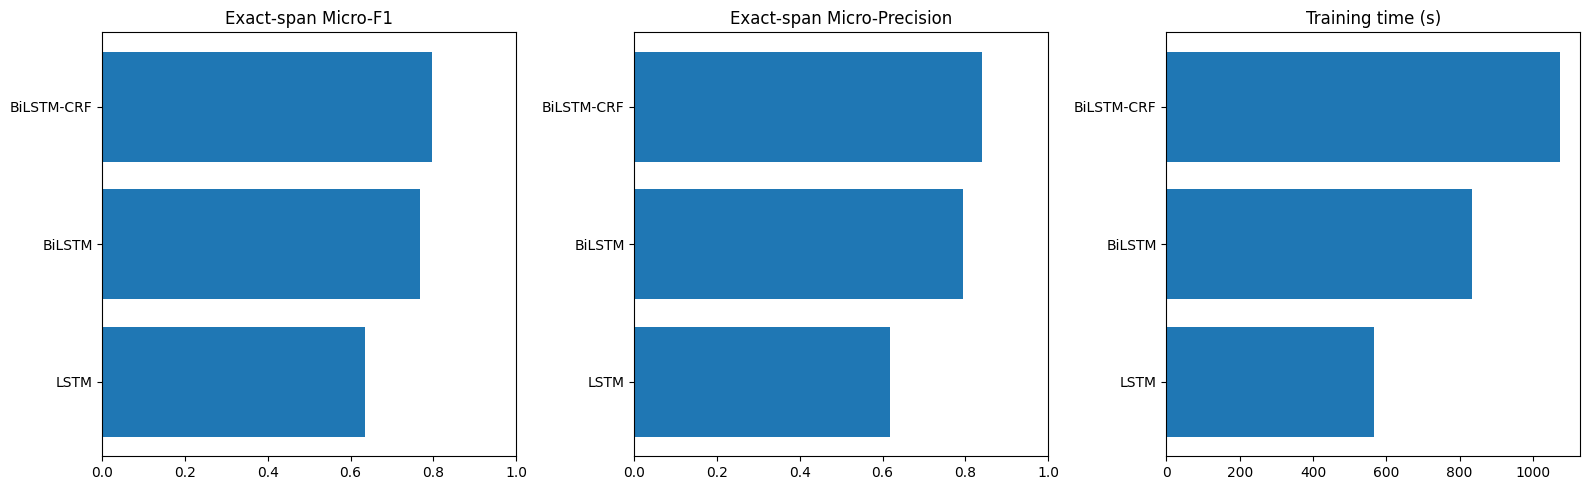

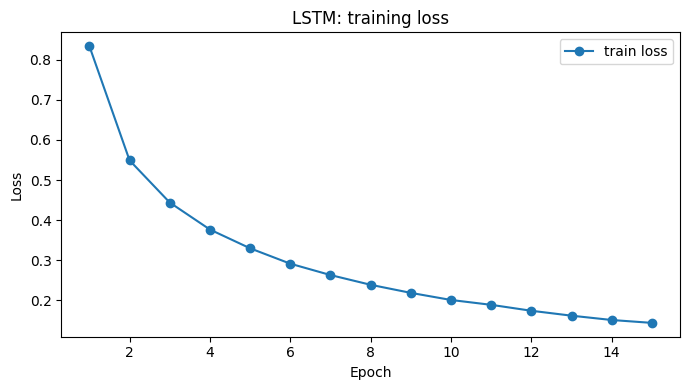

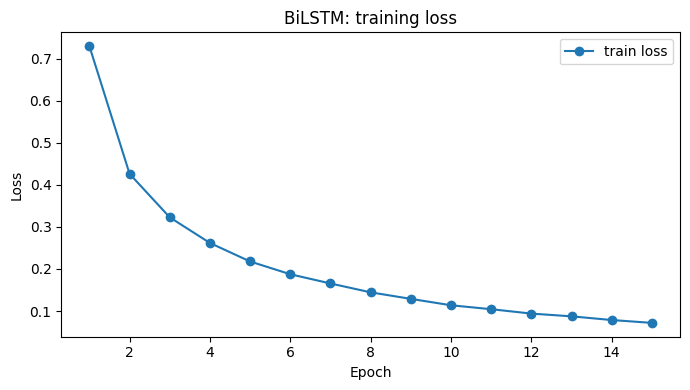

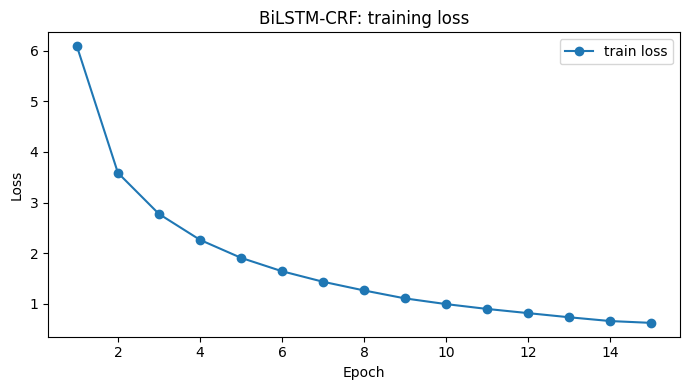

In [16]:
leader_rows=[]; test_predictions={}; test_details={}
for name,model in trained_models.items():
    started=time.perf_counter(); evaluated=evaluate_loader(model,test_loader,test_rows); infer_sec=time.perf_counter()-started
    test_predictions[name]=evaluated["predictions"]; d=evaluated["spans"]; test_details[name]=d
    train_row=next(x for x in training_results if x["model_name"]==name)
    leader_rows.append({**train_row,"test_entity_micro_precision":d["precision"],"test_entity_micro_recall":d["recall"],
                        "test_entity_micro_f1":d["f1"],"gold_entities":d["gold_entities"],
                        "predicted_entities":d["predicted_entities"],"exact_true_positives":d["true_positive"],
                        "test_token_accuracy":evaluated["token_accuracy"],"test_inference_seconds":infer_sec})
leaderboard=pd.DataFrame(leader_rows).sort_values("test_entity_micro_f1",ascending=False).reset_index(drop=True)
display(leaderboard)
leaderboard.to_csv(OUT_DIR/"model_comparison.csv",index=False)

per_type=[]
for name,d in test_details.items():
    frame=d["per_type"].copy(); frame.insert(0,"model_name",name); per_type.append(frame)
per_type_df=pd.concat(per_type,ignore_index=True)
display(per_type_df)
per_type_df.to_csv(OUT_DIR/"per_type_entity_metrics.csv",index=False)

fig,axs=plt.subplots(1,3,figsize=(16,5))
plot_df=leaderboard.sort_values("test_entity_micro_f1")
axs[0].barh(plot_df.model_name,plot_df.test_entity_micro_f1); axs[0].set_xlim(0,1); axs[0].set_title("Exact-span Micro-F1")
axs[1].barh(plot_df.model_name,plot_df.test_entity_micro_precision); axs[1].set_xlim(0,1); axs[1].set_title("Exact-span Micro-Precision")
axs[2].barh(plot_df.model_name,plot_df.training_seconds); axs[2].set_title("Training time (s)")
plt.tight_layout(); plt.show()
for name,hist in histories.items():
    plt.figure(figsize=(7,4)); plt.plot(hist.epoch,hist.train_loss,marker="o",label="train loss")
    plt.title(f"{name}: training loss"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.tight_layout(); plt.show()

## 7. Supplementary token-level classification reports

These reports are useful for diagnosing tag-level behavior, but must not replace exact entity-span metrics in the report. For example, a correct `B-ORG` followed by a missed final token can look mostly correct at token level while the entity is completely incorrect under exact-span evaluation.

In [17]:
for name,pred_seqs in test_predictions.items():
    gold_flat=[]; pred_flat=[]
    for row,pred in zip(test_rows,pred_seqs):
        gold_flat.extend(row_tags(row)); pred_flat.extend(pred)
    print("\n"+"="*64+f"\n{name} — token-level report (supplementary)")
    print(classification_report(gold_flat,pred_flat,labels=tag_names,digits=4,zero_division=0))


LSTM — token-level report (supplementary)
              precision    recall  f1-score   support

           O     0.9671    0.9832    0.9751     38315
       B-PER     0.7985    0.7661    0.7820      1086
       I-PER     0.6667    0.1714    0.2727        70
       E-PER     0.8049    0.9006    0.8501      1086
       S-PER     0.5809    0.2637    0.3627       531
       B-ORG     0.3234    0.4508    0.3766       579
       I-ORG     0.4109    0.3242    0.3624       256
       E-ORG     0.6710    0.6200    0.6445       579
       S-ORG     0.8073    0.5499    0.6542      1082
       B-LOC     0.5526    0.5431    0.5478       232
       I-LOC     0.0000    0.0000    0.0000        25
       E-LOC     0.5855    0.6940    0.6351       232
       S-LOC     0.8267    0.8308    0.8288      1436
      B-MISC     0.3069    0.1751    0.2230       177
      I-MISC     0.1622    0.1538    0.1579        39
      E-MISC     0.7239    0.5480    0.6238       177
      S-MISC     0.7935    0.6952    0

## 8. Representative error analysis

The error table compares unmatched gold and predicted spans in each sentence. It identifies exact-boundary type mistakes, overlapping boundary mistakes, combined boundary/type mistakes, missed gold entities, and spurious predicted entities. Any non-exact prediction remains an error in the official exact-span metric.

In [18]:
def error_analysis(rows,gold_sequences,pred_sequences):
    out=[]
    for si,(row,gold_tags,pred_tags) in enumerate(zip(rows,gold_sequences,pred_sequences)):
        gs=tags_to_spans(gold_tags); ps=tags_to_spans(pred_tags)
        matched=set(gs)&set(ps); unmatched_g=[x for x in gs if x not in matched]; unmatched_p=[x for x in ps if x not in matched]
        used_p=set()
        for gstart,gend,gtype in unmatched_g:
            candidates=[]
            for j,(pstart,pend,ptype) in enumerate(unmatched_p):
                if j in used_p: continue
                overlap=max(gstart,pstart)<min(gend,pend)
                same_bounds=(gstart==pstart and gend==pend)
                if overlap or same_bounds:
                    priority=0 if same_bounds else (1 if gtype==ptype else 2)
                    candidates.append((priority,j,pstart,pend,ptype))
            base={"sentence_index":si,"gold_text":" ".join(row["tokens"][gstart:gend]),"gold_type":gtype,
                  "gold_start":gstart,"gold_end_exclusive":gend,"sentence":" ".join(row["tokens"])}
            if candidates:
                _,j,pstart,pend,ptype=sorted(candidates)[0]; used_p.add(j)
                if gstart==pstart and gend==pend and gtype!=ptype: kind="incorrect_entity_type"
                elif gtype==ptype: kind="incorrect_boundary"
                else: kind="boundary_and_type_mismatch"
                out.append({**base,"error_type":kind,"predicted_text":" ".join(row["tokens"][pstart:pend]),
                            "predicted_type":ptype,"predicted_start":pstart,"predicted_end_exclusive":pend})
            else:
                out.append({**base,"error_type":"missed_entity","predicted_text":"","predicted_type":"",
                            "predicted_start":None,"predicted_end_exclusive":None})
        for j,(pstart,pend,ptype) in enumerate(unmatched_p):
            if j in used_p: continue
            out.append({"sentence_index":si,"gold_text":"","gold_type":"","gold_start":None,"gold_end_exclusive":None,
                        "error_type":"spurious_prediction","predicted_text":" ".join(row["tokens"][pstart:pend]),
                        "predicted_type":ptype,"predicted_start":pstart,"predicted_end_exclusive":pend,
                        "sentence":" ".join(row["tokens"])})
    return pd.DataFrame(out)

gold_test=[row_tags(r) for r in test_rows]
error_frames=[]
for name,pred in test_predictions.items():
    frame=error_analysis(test_rows,gold_test,pred); frame.insert(0,"model_name",name); error_frames.append(frame)
errors_df=pd.concat(error_frames,ignore_index=True)
errors_df.to_csv(OUT_DIR/"entity_error_analysis.csv",index=False)
print("Error counts:")
display(errors_df.groupby(["model_name","error_type"]).size().rename("count").reset_index())
print("Representative examples (up to 8 for each model and error type):")
display(errors_df.groupby(["model_name","error_type"],group_keys=False).head(8).reset_index(drop=True))

Error counts:


,model_name,error_type,count
0,BiLSTM,boundary_and_type_mismatch,122
1,BiLSTM,incorrect_boundary,271
2,BiLSTM,incorrect_entity_type,307
3,BiLSTM,missed_entity,743
4,BiLSTM,spurious_prediction,390
5,BiLSTM-CRF,boundary_and_type_mismatch,145
6,BiLSTM-CRF,incorrect_boundary,166
7,BiLSTM-CRF,incorrect_entity_type,298
8,BiLSTM-CRF,missed_entity,769
9,BiLSTM-CRF,spurious_prediction,203


Representative examples (up to 8 for each model and error type):


,model_name,sentence_index,gold_text,gold_type,gold_start,gold_end_exclusive,sentence,error_type,predicted_text,predicted_type,predicted_start,predicted_end_exclusive
0,LSTM,0,CHINA,PER,7.0,8.0,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI...",incorrect_entity_type,CHINA,LOC,7.0,8.0
1,LSTM,1,Nadim Ladki,PER,0.0,2.0,Nadim Ladki,incorrect_boundary,Ladki,PER,1.0,2.0
2,LSTM,1,,,NaN,NaN,Nadim Ladki,spurious_prediction,Nadim,ORG,0.0,1.0
3,LSTM,2,AL-AIN,LOC,0.0,1.0,"AL-AIN , United Arab Emirates 1996-12-06",incorrect_entity_type,AL-AIN,ORG,0.0,1.0
4,LSTM,2,United Arab Emirates,LOC,2.0,5.0,"AL-AIN , United Arab Emirates 1996-12-06",incorrect_boundary,United Arab,LOC,2.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...
115,BiLSTM-CRF,335,Allan Budi Kusuma,PER,11.0,14.0,Wijaya -LPR- Indonesia -RPR- ; Sun Jun -LPR- C...,boundary_and_type_mismatch,Allan Budi,ORG,11.0,13.0
116,BiLSTM-CRF,385,PACIFIC,LOC,0.0,1.0,PACIFIC DIVISION,boundary_and_type_mismatch,PACIFIC DIVISION,MISC,0.0,2.0
117,BiLSTM-CRF,408,League,ORG,0.0,1.0,League games on Thursday -LPR- home team in CA...,boundary_and_type_mismatch,League games,MISC,0.0,2.0
118,BiLSTM-CRF,421,Washington Redskins,ORG,14.0,16.0,"Philadelphia , which fell from an NFC East tie...",boundary_and_type_mismatch,Washington,LOC,14.0,15.0


In [19]:
def readable_spans(tokens,tags):
    return [{"text":" ".join(tokens[s:e]),"type":t,"start":s,"end_exclusive":e} for s,e,t in tags_to_spans(tags)]

best_model=str(leaderboard.iloc[0]["model_name"])
best_pred=test_predictions[best_model]
examples=[]
for i,(row,gold,pred) in enumerate(zip(test_rows,gold_test,best_pred)):
    gold_entities=readable_spans(row["tokens"],gold); pred_entities=readable_spans(row["tokens"],pred)
    if gold_entities != pred_entities:
        examples.append({"sentence_index":i,"sentence":" ".join(row["tokens"]),
                         "tokens":json.dumps(row["tokens"],ensure_ascii=False),
                         "gold_tags":json.dumps(gold,ensure_ascii=False),"predicted_tags":json.dumps(pred,ensure_ascii=False),
                         "gold_entities":json.dumps(gold_entities,ensure_ascii=False),
                         "predicted_entities":json.dumps(pred_entities,ensure_ascii=False)})
sentence_errors=pd.DataFrame(examples)
sentence_errors.to_csv(OUT_DIR/"best_model_sentence_errors.csv",index=False)
print("Best model by test exact-span Micro-F1 (descriptive):",best_model)
display(sentence_errors.head(25))

Best model by test exact-span Micro-F1 (descriptive): BiLSTM-CRF


,sentence_index,sentence,tokens,gold_tags,predicted_tags,gold_entities,predicted_entities
0,0,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI...","[""SOCCER"", ""-"", ""JAPAN"", ""GET"", ""LUCKY"", ""WIN""...","[""O"", ""O"", ""S-LOC"", ""O"", ""O"", ""O"", ""O"", ""S-PER...","[""O"", ""O"", ""S-LOC"", ""O"", ""O"", ""O"", ""O"", ""S-LOC...","[{""text"": ""JAPAN"", ""type"": ""LOC"", ""start"": 2, ...","[{""text"": ""JAPAN"", ""type"": ""LOC"", ""start"": 2, ..."
1,1,Nadim Ladki,"[""Nadim"", ""Ladki""]","[""B-PER"", ""E-PER""]","[""B-ORG"", ""E-ORG""]","[{""text"": ""Nadim Ladki"", ""type"": ""PER"", ""start...","[{""text"": ""Nadim Ladki"", ""type"": ""ORG"", ""start..."
2,4,But China saw their luck desert them in the se...,"[""But"", ""China"", ""saw"", ""their"", ""luck"", ""dese...","[""O"", ""S-LOC"", ""O"", ""O"", ""O"", ""O"", ""O"", ""O"", ""...","[""O"", ""S-LOC"", ""O"", ""O"", ""O"", ""O"", ""O"", ""O"", ""...","[{""text"": ""China"", ""type"": ""LOC"", ""start"": 1, ...","[{""text"": ""China"", ""type"": ""LOC"", ""start"": 1, ..."
3,5,China controlled most of the match and saw sev...,"[""China"", ""controlled"", ""most"", ""of"", ""the"", ""...","[""S-LOC"", ""O"", ""O"", ""O"", ""O"", ""O"", ""O"", ""O"", ""...","[""S-LOC"", ""O"", ""O"", ""O"", ""O"", ""O"", ""O"", ""O"", ""...","[{""text"": ""China"", ""type"": ""LOC"", ""start"": 0, ...","[{""text"": ""China"", ""type"": ""LOC"", ""start"": 0, ..."
4,8,Despite winning the Asian Games title two year...,"[""Despite"", ""winning"", ""the"", ""Asian"", ""Games""...","[""O"", ""O"", ""O"", ""B-MISC"", ""E-MISC"", ""O"", ""O"", ...","[""O"", ""O"", ""O"", ""S-MISC"", ""O"", ""O"", ""O"", ""O"", ...","[{""text"": ""Asian Games"", ""type"": ""MISC"", ""star...","[{""text"": ""Asian"", ""type"": ""MISC"", ""start"": 3,..."
5,10,Takuya Takagi scored the winner in the 88th mi...,"[""Takuya"", ""Takagi"", ""scored"", ""the"", ""winner""...","[""B-PER"", ""E-PER"", ""O"", ""O"", ""O"", ""O"", ""O"", ""O...","[""B-PER"", ""E-PER"", ""O"", ""O"", ""O"", ""O"", ""O"", ""O...","[{""text"": ""Takuya Takagi"", ""type"": ""PER"", ""sta...","[{""text"": ""Takuya Takagi"", ""type"": ""PER"", ""sta..."
6,12,Defender Hassan Abbas rose to intercept a long...,"[""Defender"", ""Hassan"", ""Abbas"", ""rose"", ""to"", ...","[""O"", ""B-PER"", ""E-PER"", ""O"", ""O"", ""O"", ""O"", ""O...","[""O"", ""B-PER"", ""E-PER"", ""O"", ""O"", ""O"", ""O"", ""O...","[{""text"": ""Hassan Abbas"", ""type"": ""PER"", ""star...","[{""text"": ""Hassan Abbas"", ""type"": ""PER"", ""star..."
7,14,Japan then laid siege to the Syrian penalty ar...,"[""Japan"", ""then"", ""laid"", ""siege"", ""to"", ""the""...","[""S-LOC"", ""O"", ""O"", ""O"", ""O"", ""O"", ""S-MISC"", ""...","[""S-LOC"", ""O"", ""B-PER"", ""E-PER"", ""O"", ""O"", ""S-...","[{""text"": ""Japan"", ""type"": ""LOC"", ""start"": 0, ...","[{""text"": ""Japan"", ""type"": ""LOC"", ""start"": 0, ..."
8,15,Bitar pulled off fine saves whenever they did .,"[""Bitar"", ""pulled"", ""off"", ""fine"", ""saves"", ""w...","[""S-PER"", ""O"", ""O"", ""O"", ""O"", ""O"", ""O"", ""O"", ""O""]","[""O"", ""O"", ""O"", ""O"", ""O"", ""O"", ""O"", ""O"", ""O""]","[{""text"": ""Bitar"", ""type"": ""PER"", ""start"": 0, ...",[]
9,16,Japan coach Shu Kamo said : ' ' The Syrian own...,"[""Japan"", ""coach"", ""Shu"", ""Kamo"", ""said"", "":"",...","[""S-LOC"", ""O"", ""B-PER"", ""E-PER"", ""O"", ""O"", ""O""...","[""S-LOC"", ""O"", ""B-PER"", ""E-PER"", ""O"", ""O"", ""O""...","[{""text"": ""Japan"", ""type"": ""LOC"", ""start"": 0, ...","[{""text"": ""Japan"", ""type"": ""LOC"", ""start"": 0, ..."


## 9. Export summary and downloadable output archive

The result summary is created after training from actual metrics. The notebook is delivered untrained, so no performance numbers are asserted before it runs.

In [20]:
summary={"dataset":"extraordinarylab/conll2003","annotation_scheme":SCHEME,"entity_types":ENTITY_TYPES,
         "seed":SEED,"device":str(DEVICE),"normalization":NORMALIZATION,"vocab_size":VOCAB_SIZE,
         "tag_names":tag_names,"split_sizes":{"train":len(train_rows),"validation":len(val_rows),"test":len(test_rows)},
         "best_by_test_entity_micro_f1_descriptive":best_model,"models":leaderboard.to_dict(orient="records"),
         "input_files":{k:(str(v) if v else None) for k,v in FILE_PATHS.items()},
         "generated_utc":datetime.now(timezone.utc).isoformat()}
with open(OUT_DIR/"run_summary.json","w",encoding="utf-8") as f:
    json.dump(summary,f,ensure_ascii=False,indent=2,default=str)
zip_path=shutil.make_archive("ner_outputs","zip",root_dir=OUT_DIR)
print(json.dumps(summary,ensure_ascii=False,indent=2,default=str)[:10000])
print("\nSaved artifacts:")
for p in sorted(OUT_DIR.iterdir()): print(f"- {p.name} ({p.stat().st_size/1024:.1f} KB)")
print("Output archive:",zip_path)

{
  "dataset": "extraordinarylab/conll2003",
  "annotation_scheme": "BIOES",
  "entity_types": [
    "PER",
    "ORG",
    "LOC",
    "MISC"
  ],
  "seed": 42,
  "device": "cpu",
  "normalization": "lowercase_digit0",
  "vocab_size": 17494,
  "tag_names": [
    "O",
    "B-PER",
    "I-PER",
    "E-PER",
    "S-PER",
    "B-ORG",
    "I-ORG",
    "E-ORG",
    "S-ORG",
    "B-LOC",
    "I-LOC",
    "E-LOC",
    "S-LOC",
    "B-MISC",
    "I-MISC",
    "E-MISC",
    "S-MISC"
  ],
  "split_sizes": {
    "train": 14041,
    "validation": 3250,
    "test": 3453
  },
  "best_by_test_entity_micro_f1_descriptive": "BiLSTM-CRF",
  "models": [
    {
      "model_name": "BiLSTM-CRF",
      "best_epoch": 15,
      "validation_entity_micro_f1": 0.8572433811241094,
      "training_seconds": 1074.7858800590002,
      "trainable_parameters": 1989612,
      "test_entity_micro_precision": 0.8402203856749312,
      "test_entity_micro_recall": 0.7560198300283286,
      "test_entity_micro_f1": 0.7958993476

## 10. Report checklist

In your midterm write-up, report: (1) CoNLL-2003 dataset and four types PER/ORG/LOC/MISC; (2) BIOES/BIO format, token-label alignment and padding masks; (3) normalization decision and measured OOV rates; (4) LSTM/BiLSTM/BiLSTM-CRF architectures, parameter counts, best epochs and runtime; (5) exact entity-level micro Precision/Recall/F1 and per-type scores; (6) selected errors from `entity_error_analysis.csv`, especially missed spans, boundaries and entity types; and (7) limitations such as OOV behavior and lack of pretrained contextual embeddings.

The uploaded summary reports 14,041 train sentences / 203,618 tokens, 3,250 validation sentences / 51,360 tokens, and 3,453 test sentences / 46,427 tokens. The notebook recomputes all counts from the actual local files; use the notebook output if they differ.